# Template matching

In [12]:
import cv2
from matplotlib import pyplot as plt

plt.gray()

<Figure size 640x480 with 0 Axes>

The goal of template matching is to find the location of a template image in a larger image. Thus to perform template matching, or block matching, we initially need an image containing some feature (e.g. an object) to locate.
For this exercise we will be using one of the images of a playtable and for simplicity we will be focusing on single channel images (grayscale images).

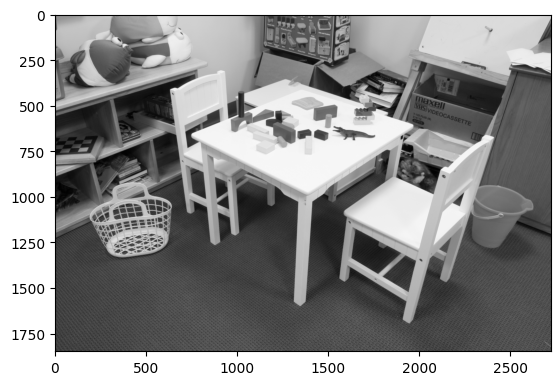

In [13]:
# Load the main scene image we'll search within, and prepare a grayscale
# version of it.
# cv2.matchTemplate() (used below) compares a template against a search image;
# keeping both simple (single-channel) reduces the problem to comparing
# intensity patterns rather than full color patterns, which is enough to locate
# a template robustly and keeps the computation faster than working across 3
# color channels.
img = cv2.imread("playtable_left.png")

img_left = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray_left = cv2.cvtColor(img_left, cv2.COLOR_RGB2GRAY)

plt.imshow(gray_left)


The second thing we need is a template containing the features or object that we are interested in locating.

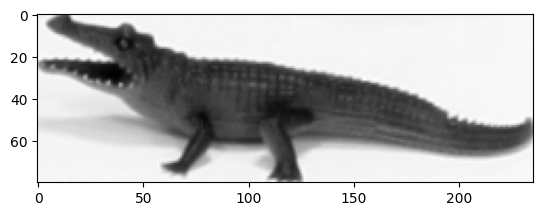

In [14]:
# Load the template image (the crocodile) that we want to locate inside
# the larger scene image.
# Why take template[...,0]: even though this particular template was
# originally saved as a grayscale image, cv2.imread() still loads it as a
# 3-channel image by default, with the same grayscale value duplicated across
# all three channels. Since all three channels are identical, we can simply
# keep one of them (channel 0) to get back to a genuine single-channel image.
# Matching the grayscale search image ('gray_left') hat matchTemplate needs to
# compare against.
template = cv2.imread('crocodile.png')
# Though the template is saved as a single channel (grayscale) image, it is
# loaded as a 3 channel image with identical channels. Therefore we can just
# take any of the three channels.
template = template[...,0]
plt.imshow(template)

With both an image and a template, we can perform template matching to locate the crocodile in the large playtable image.

## Exercise 1.1
We will use a normalized cross correlation as a similarity metric defined [here](https://docs.opencv.org/4.x/df/dfb/group__imgproc__object.html#ga3a7850640f1fe1f58fe91a2d7583695d).

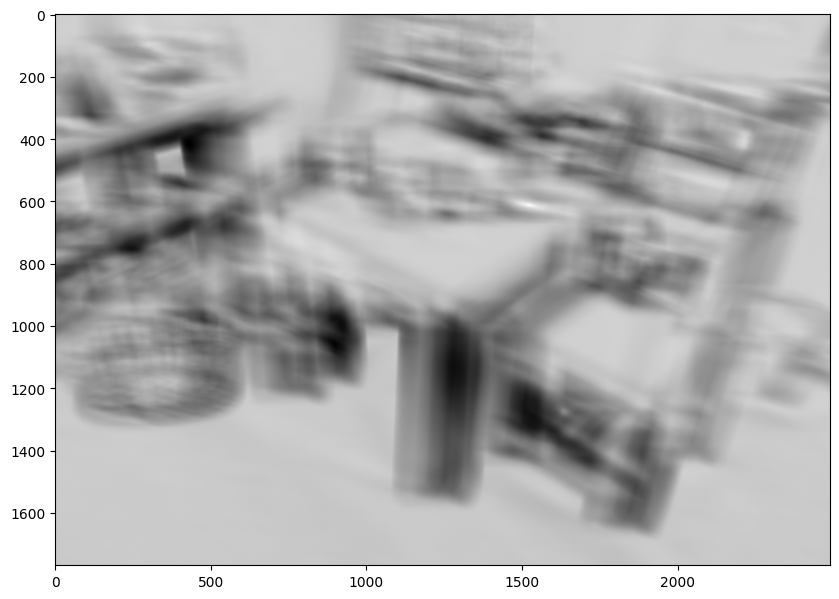

In [ ]:
# Run template matching using Normalized Cross-Correlation.
# cv2.matchTemplate(): this slides the template across every possible
# position in the search image and, at each position, computes a similarity
# score between the template and the underlying image patch. The result is a 2D
# "similarity map" the same general size as the search image (slightly smaller,
# since the template can't be centered outside the image bounds).
# Why TM_CCORR_NORMED specifically: normalized cross-correlation measures
# how well the template's pattern of intensities correlates with each image
# patch, normalized so that the result isn't affected by the overall brightness
# of the patch. Tthis makes it a good general-purpose similarity metric less
# sensitive to lighting differences between the template and the target region
# than an un-normalized comparison would be. Higher values indicate a stronger
# match. The similarity map is plotted directly. Brighter regions correspond to
# image locations that look more similar to the template.
res = cv2.matchTemplate(gray_left, template, cv2.TM_CCORR_NORMED)
plt.figure(figsize = (10,10))
plt.imshow(res, 'gray')

What does the above image tell us?

We can use the minMaxLoc() function to find the location which best matches our template and draw a rectangle around it. 

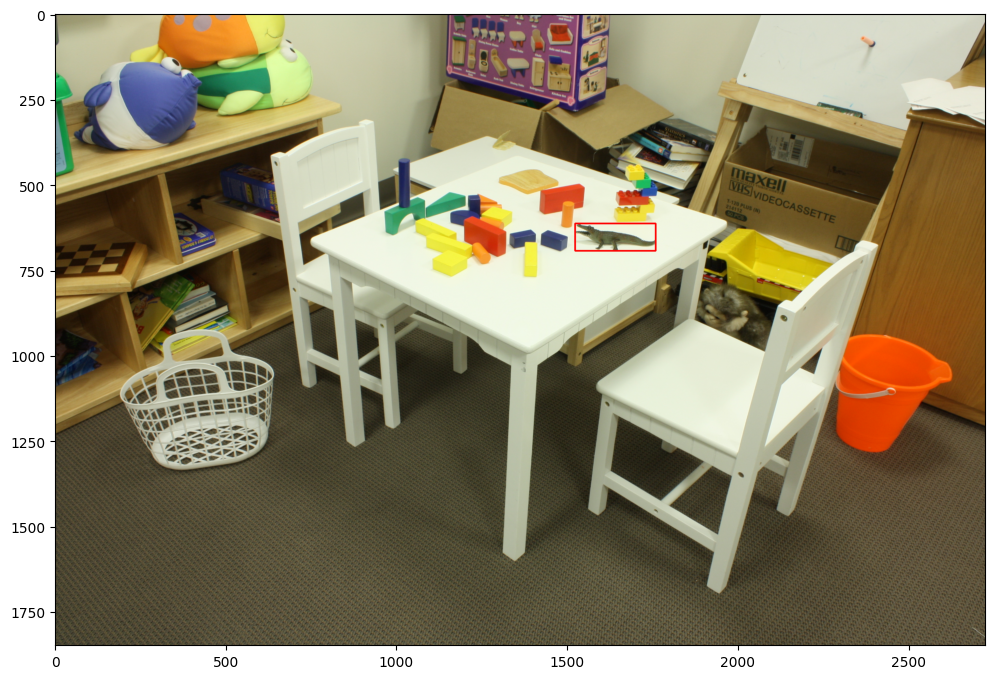

In [ ]:
# Locate the best match and draw a box around it.
# Why cv2.minMaxLoc(): rather than visually inspecting the similarity map to
# find the brightest spot, this function directly returns the minimum and
# maximum values in the map along with their pixel locations. Since
# TM_CCORR_NORMED gives higher values for better matches, the position we
# want is 'max_loc'.
# How the bounding box is built: 'max_loc' gives the top-left corner of
# the best-matching region (matchTemplate results are indexed by the
# template's top-left corner as it slides across the image), so we
# compute the bottom-right corner by simply adding the template's
# width/height to that point. cv2.rectangle() then draws a red
# ((255, 0, 0) in RGB) box of 3-pixel thickness on a copy of the original
# color image (img_left.copy(), so we don't modify the original).
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

top_left = max_loc
bottom_right = (top_left[0] + template.shape[1], top_left[1] + template.shape[0])

crocodile = cv2.rectangle(img_left.copy(), top_left, bottom_right, (255,0,0), 3)

plt.figure(figsize=(12,12))
plt.imshow(crocodile)


## Exercise 1.2
Use template matching to locate the orange bucket in the center-right side of `playtable_left.png`

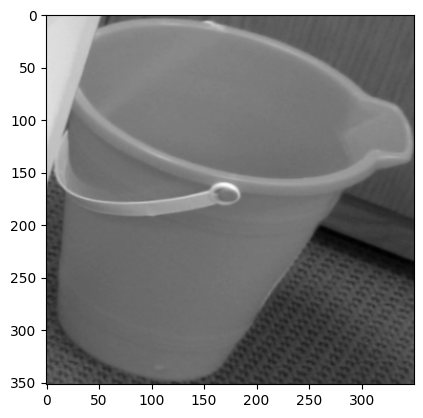

In [17]:
# Load a new template (the orange bucket) to search for.
template = cv2.imread('orange_bucket.png')
template = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)
plt.imshow(template)

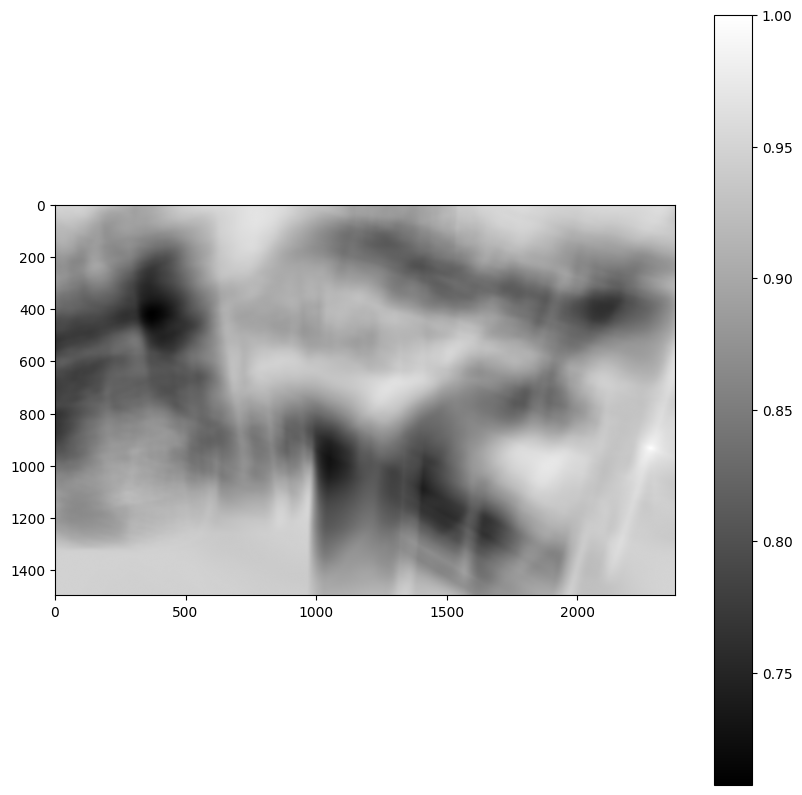

In [18]:
# Run template matching for the bucket, same method as Exercise 1.1. Adding a
# colorbar here makes it easier to read the actual similarity values in the map
# (not just relative brightness), which is useful for comparing how sharply
# peaked/confident this match is compared to others.
res = cv2.matchTemplate(gray_left, template, cv2.TM_CCORR_NORMED)
plt.figure(figsize = (10,10))
plt.imshow(res, 'gray')
plt.colorbar()

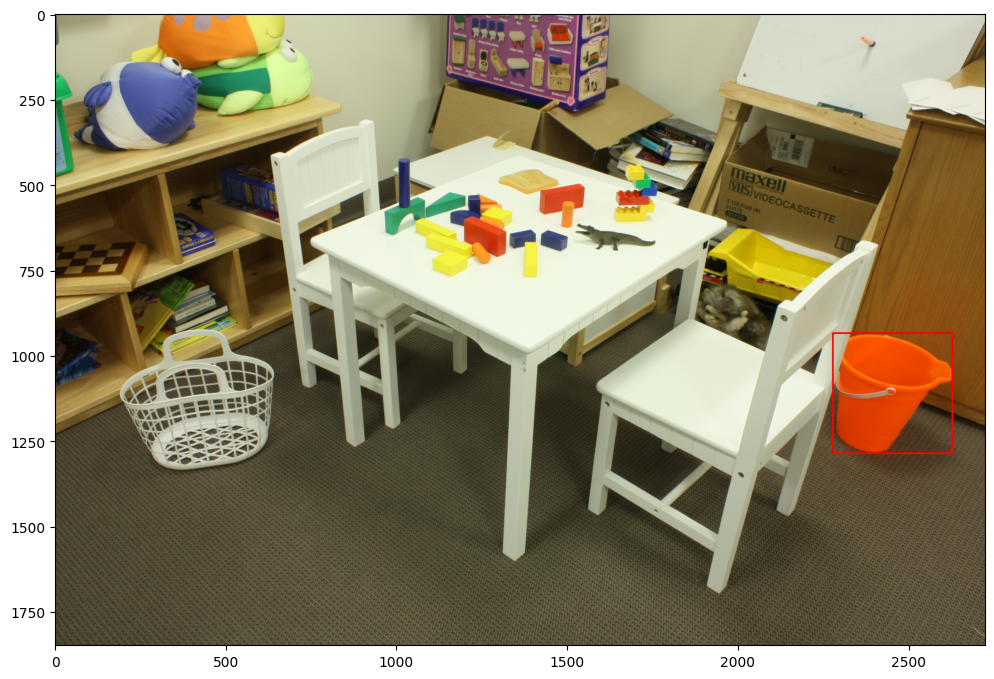

In [19]:
# Locate and draw a box around the best-matching location for the bucket
# template, using the exact same minMaxLoc + rectangle approach as in
# Exercise 1.1 (see that cell for the full explanation).
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

top_left = max_loc
bottom_right = (top_left[0] + template.shape[1], top_left[1] + template.shape[0])

bucket = cv2.rectangle(img_left.copy(), top_left, bottom_right, (255,0,0), 3)

plt.figure(figsize=(12,12))
plt.imshow(bucket)

## Exercise 1.3
In the above examples, we used normalized cross correlation as the metric to create our similarity map. You can find the mathematical description [here](https://docs.opencv.org/4.x/df/dfb/group__imgproc__object.html#ga3a7850640f1fe1f58fe91a2d7583695d). In the same link you will also find other similarity metrics.

Try to use the squared difference `cv2.TM_SQDIFF` instead and compare it to the above result.

**Hint:** plot the results next to each other.

**NOTE:** Based on the definitions in the above link, we see that `cv2.TM_SQDIFF` gives a low value for a good match, i.e. we have to look for the lowest value in the similarity map instead of the maximum value like we did with `cv2.TM_CCORR_NORMED`.

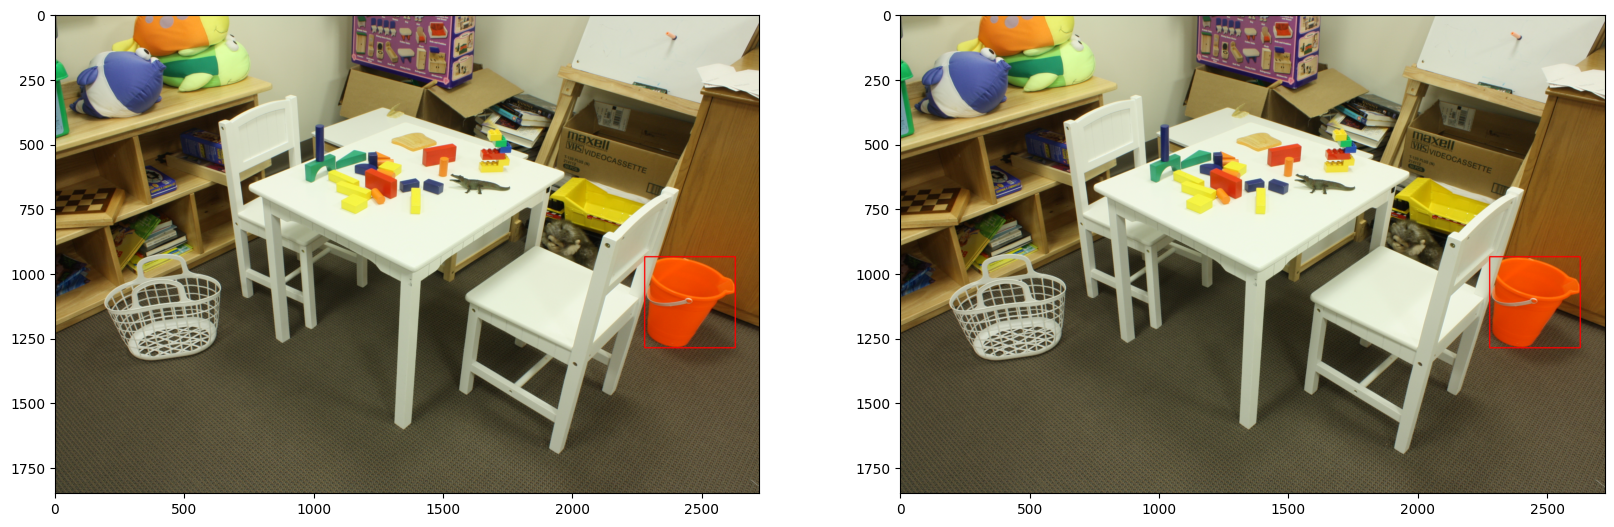

In [20]:
# Why TM_SQDIFF is handled differently: this metric measures the sum of square
# pixel-intensity differences between the template and each image patch. The
# smaller the difference, the better the match. This is the opposite convention
# from TM_CCORR_NORMED (where higher = better), which is why we take 'min_loc'
# (not 'max_loc') as the best match position for the SQDIFF result. Both
# similarity maps and their resulting bounding boxes are computed side by side
# using the same template and search image, then displayed next to each other
# (via plt.subplots(1, 2, ...)) so their detected bounding boxes can be
# visually compared directly.
template = cv2.imread('orange_bucket.png')
template = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

res_ncc = cv2.matchTemplate(gray_left, template, cv2.TM_CCORR_NORMED)
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res_ncc)
top_left = max_loc
bottom_right = (top_left[0] + template.shape[1], top_left[1] + template.shape[0])
bucket_ncc = cv2.rectangle(img_left.copy(), top_left, bottom_right, (255,0,0), 3)
axes[0].imshow(bucket_ncc)

res_sqdiff = cv2.matchTemplate(gray_left, template, cv2.TM_SQDIFF)
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res_sqdiff)
top_left = min_loc
bottom_right = (top_left[0] + template.shape[1], top_left[1] + template.shape[0])
bucket_sqdiff = cv2.rectangle(img_left.copy(), top_left, bottom_right, (255,0,0), 3)
axes[1].imshow(bucket_sqdiff)

plt.show()

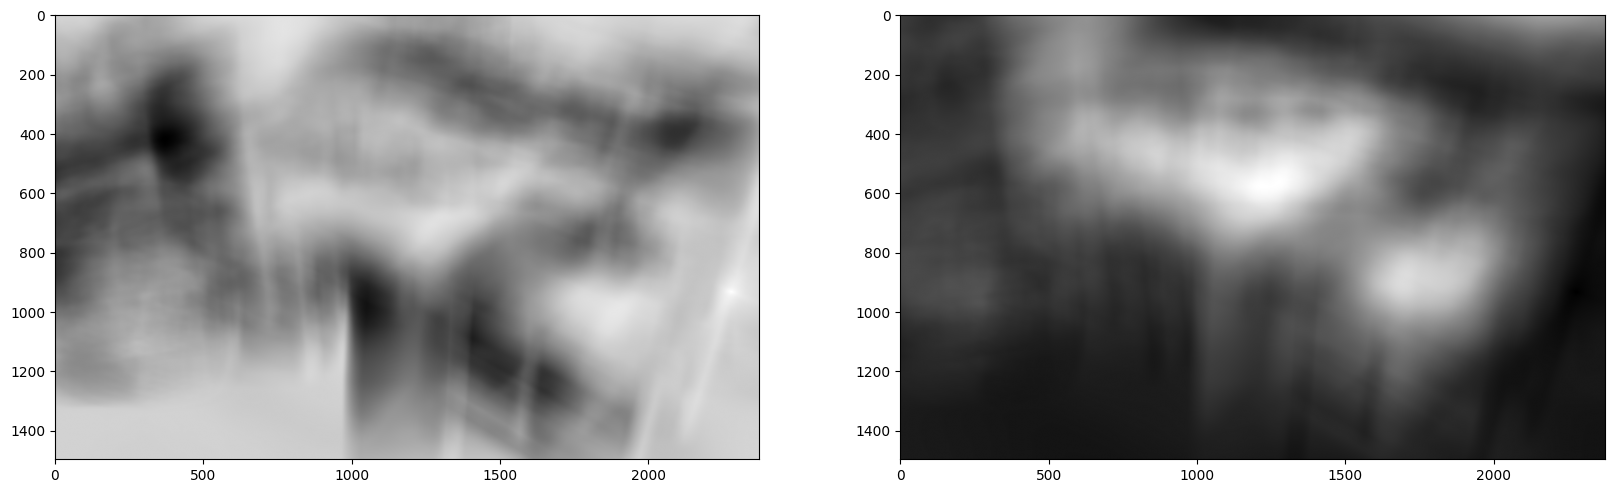

In [21]:
# Visualizing 'res_ncc' and 'res_sqdiff' next to each other shows how
# differently each metric responds across the image.
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].imshow(res_ncc, 'gray')
axes[1].imshow(res_sqdiff, 'gray')
plt.show()